In [ ]:
from google.colab import files
uploaded = files.upload()


Saving bookings.csv to bookings.csv
Saving calendar.csv to calendar.csv
Saving facilities.csv to facilities.csv
Saving maintenance.csv to maintenance.csv
Saving occupancy.csv to occupancy.csv


In [ ]:

import os

# The CSV files were uploaded individually
DATA_DIR = "/content"

required_files = [
    "bookings.csv",
    "facilities.csv",
    "occupancy.csv",
    "calendar.csv",
    "maintenance.csv"
]

# Verify that all files exist
for file in required_files:
    path = os.path.join(DATA_DIR, file)
    if os.path.exists(path):
        print(f"✅ Found: {file}")
    else:
        print(f"❌ Missing: {file}")

missing = [
    file for file in required_files
    if not os.path.exists(os.path.join(DATA_DIR, file))
]

if missing:
    raise FileNotFoundError(f"Please upload these files: {missing}")

print("\n🎉 All five CSV files are ready!")


✅ Found: bookings.csv
✅ Found: facilities.csv
✅ Found: occupancy.csv
✅ Found: calendar.csv
✅ Found: maintenance.csv

🎉 All five CSV files are ready!


In [ ]:

import pandas as pd
from IPython.display import display

bookings = pd.read_csv("/content/bookings.csv")
facilities = pd.read_csv("/content/facilities.csv")
occupancy = pd.read_csv("/content/occupancy.csv")
calendar = pd.read_csv("/content/calendar.csv")
maintenance = pd.read_csv("/content/maintenance.csv")

for name, df in [
    ("bookings", bookings),
    ("facilities", facilities),
    ("occupancy", occupancy),
    ("calendar", calendar),
    ("maintenance", maintenance)
]:
    print(f"\n{name}: {df.shape[0]} records × {df.shape[1]} attributes")
    display(df.head(3))



bookings: 2337 records × 6 attributes


,booking_id,facility,date,start,end,purpose
0,B000001,Lecture Hall A,2026-01-05,17:00,19:00,Workshop
1,B000002,Lecture Hall A,2026-01-05,11:00,12:00,Lecture
2,B000003,Lecture Hall A,2026-01-05,15:00,16:00,Lecture



facilities: 12 records × 5 attributes


,facility_id,facility,type,capacity,block
0,F001,Lecture Hall A,Classroom,120,Block A
1,F002,Lecture Hall B,Classroom,90,Block A
2,F003,Smart Classroom 1,Classroom,60,Block B



occupancy: 6480 records × 3 attributes


,timestamp,facility,count
0,2026-01-05 08:00:00,Lecture Hall A,57.0
1,2026-01-05 10:00:00,Lecture Hall A,68.0
2,2026-01-05 12:00:00,Lecture Hall A,49.0



calendar: 90 records × 4 attributes


,date,working_day,event,exam_period
0,2026-01-05,True,Regular Day,False
1,2026-01-06,True,Regular Day,False
2,2026-01-07,True,Regular Day,False



maintenance: 61 records × 5 attributes


,maintenance_id,facility,issue,downtime_hours,date
0,M00001,Lecture Hall A,Projector failure,2.0,2026-01-30
1,M00002,Lecture Hall A,Projector failure,0.0,2026-01-22
2,M00003,Lecture Hall A,Air conditioning,6.0,2026-03-03


In [ ]:
# 2. Initial data quality checks
datasets = {'bookings': bookings, 'facilities': facilities, 'occupancy': occupancy,
            'calendar': calendar, 'maintenance': maintenance}
quality = []
for name, df in datasets.items():
    quality.append({
        'dataset': name,
        'records': len(df),
        'attributes': len(df.columns),
        'missing_cells': int(df.isna().sum().sum()),
        'duplicate_rows': int(df.duplicated().sum())
    })
quality_df = pd.DataFrame(quality)
display(quality_df)


,dataset,records,attributes,missing_cells,duplicate_rows
0,bookings,2337,6,8,27
1,facilities,12,5,0,0
2,occupancy,6480,3,132,0
3,calendar,90,4,0,0
4,maintenance,61,5,11,0


In [ ]:
# 3. Data preprocessing
# Standardize facility names consistently across files.
facility_names = facilities['facility'].tolist()
name_lookup = {name.strip().lower(): name for name in facility_names}

def standardize_facility(series):
    normalized = series.astype('string').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
    return normalized.map(name_lookup).fillna(normalized)

for df in [bookings, occupancy, maintenance]:
    df['facility'] = standardize_facility(df['facility'])

# Parse dates and times.
bookings['date'] = pd.to_datetime(bookings['date'], errors='coerce')
bookings['start'] = pd.to_datetime(bookings['start'], format='%H:%M', errors='coerce')
bookings['end'] = pd.to_datetime(bookings['end'], format='%H:%M', errors='coerce')
bookings['duration_hours'] = (bookings['end'] - bookings['start']).dt.total_seconds() / 3600
bookings.loc[bookings['duration_hours'] <= 0, 'duration_hours'] = np.nan
bookings['purpose'] = bookings['purpose'].fillna('Unknown')

occupancy['timestamp'] = pd.to_datetime(occupancy['timestamp'], errors='coerce')
occupancy['count'] = pd.to_numeric(occupancy['count'], errors='coerce')
maintenance['date'] = pd.to_datetime(maintenance['date'], errors='coerce')
maintenance['downtime_hours'] = pd.to_numeric(maintenance['downtime_hours'], errors='coerce')

# Remove exact duplicates and duplicate booking IDs.
bookings = bookings.drop_duplicates().drop_duplicates(subset=['booking_id'])
occupancy = occupancy.drop_duplicates()
maintenance = maintenance.drop_duplicates()

# Fill missing occupancy values with facility-specific median; flag missing readings first.
occupancy['occupancy_was_missing'] = occupancy['count'].isna()
occupancy['count'] = occupancy.groupby('facility')['count'].transform(lambda s: s.fillna(s.median()))
occupancy['count'] = occupancy['count'].fillna(0)

# Merge capacity and cap impossible counts at capacity for utilization calculations,
# while preserving an anomaly flag and original count.
occupancy = occupancy.merge(facilities[['facility','capacity','type','block']], on='facility', how='left')
occupancy['over_capacity_flag'] = occupancy['count'] > occupancy['capacity']
occupancy['count_original_cleaned'] = occupancy['count']
occupancy['count_for_utilization'] = occupancy[['count','capacity']].min(axis=1)
occupancy['utilization_pct'] = 100 * occupancy['count_for_utilization'] / occupancy['capacity']
occupancy['hour'] = occupancy['timestamp'].dt.hour
occupancy['date'] = occupancy['timestamp'].dt.normalize()
# Calendar features are joined later using a normalized date key.
print("Cleaned shapes:")
print("Bookings:", bookings.shape, "Occupancy:", occupancy.shape, "Maintenance:", maintenance.shape)
print("Duplicate booking IDs remaining:", bookings['booking_id'].duplicated().sum())
print("Missing occupancy counts remaining:", occupancy['count'].isna().sum())
print("Over-capacity readings flagged:", int(occupancy['over_capacity_flag'].sum()))


Cleaned shapes:
Bookings: (2310, 7) Occupancy: (6480, 13) Maintenance: (61, 5)
Duplicate booking IDs remaining: 0
Missing occupancy counts remaining: 0
Over-capacity readings flagged: 66


In [ ]:

import pandas as pd
from google.colab import files

# 1. Prepare the datasets
b = bookings.copy()
f = facilities.copy()
o = occupancy.copy()
c = calendar.copy()
m = maintenance.copy()

# 2. Standardize facility names
facility_lookup = {
    name.strip().lower(): name
    for name in f["facility"].dropna().astype(str)
}

def clean_facility_names(df):
    if "facility" in df.columns:
        df["facility"] = (
            df["facility"].astype("string").str.strip()
            .str.lower().map(facility_lookup)
            .fillna(df["facility"].astype("string").str.strip())
        )
    return df

b = clean_facility_names(b)
o = clean_facility_names(o)
m = clean_facility_names(m)

# 3. Prepare occupancy data and merge capacity details
o["timestamp"] = pd.to_datetime(o["timestamp"], errors="coerce")

if "capacity" not in o.columns:
    o = o.merge(
        f[["facility", "type", "capacity", "block"]],
        on="facility", how="left"
    )

if "count" in o.columns:
    o["count"] = pd.to_numeric(o["count"], errors="coerce")
    o["occupancy_missing"] = o["count"].isna()
    o["count"] = o.groupby("facility")["count"].transform(
        lambda s: s.fillna(s.median())
    )

o["date"] = o["timestamp"].dt.strftime("%Y-%m-%d")
o["hour"] = o["timestamp"].dt.hour

# Utilization features
o["count_for_utilization"] = o["count"].clip(
    upper=o["capacity"]
)
o["utilization_pct"] = (
    o["count_for_utilization"] / o["capacity"] * 100
)

# 4. Add calendar information
c["date"] = pd.to_datetime(c["date"], errors="coerce").dt.strftime("%Y-%m-%d")

combined = o.merge(
    c, on="date", how="left", suffixes=("", "_calendar")
)

# 5. Add booking information aggregated by facility and date
b["date"] = pd.to_datetime(b["date"], errors="coerce").dt.strftime("%Y-%m-%d")

if "duration_hours" not in b.columns:
    start = pd.to_datetime(b["start"], format="%H:%M", errors="coerce")
    end = pd.to_datetime(b["end"], format="%H:%M", errors="coerce")
    b["duration_hours"] = (
        end - start
    ).dt.total_seconds() / 3600

b["duration_hours"] = b["duration_hours"].clip(lower=0)

booking_summary = b.groupby(
    ["facility", "date"], as_index=False
).agg(
    booking_count=("facility", "size"),
    total_booked_hours=("duration_hours", "sum")
)

combined = combined.merge(
    booking_summary, on=["facility", "date"], how="left"
)

combined[["booking_count", "total_booked_hours"]] = (
    combined[["booking_count", "total_booked_hours"]].fillna(0)
)

# 6. Add maintenance summary by facility
m["downtime_hours"] = pd.to_numeric(
    m["downtime_hours"], errors="coerce"
)
m["downtime_hours"] = m["downtime_hours"].fillna(
    m.groupby("facility")["downtime_hours"].transform("median")
).fillna(0)

maintenance_summary = m.groupby(
    "facility", as_index=False
).agg(
    maintenance_records=("facility", "size"),
    total_downtime_hours=("downtime_hours", "sum")
)

combined = combined.merge(
    maintenance_summary, on="facility", how="left"
)

combined[["maintenance_records", "total_downtime_hours"]] = (
    combined[["maintenance_records", "total_downtime_hours"]]
    .fillna(0)
)

# 7. Remove exact duplicate rows and export
combined = combined.drop_duplicates().reset_index(drop=True)

output_file = "/content/cleaned_combined_campus_facility.csv"
combined.to_csv(output_file, index=False)

print("Combined dataset shape:", combined.shape)
print("\nColumns:")
print(combined.columns.tolist())
display(combined.head())

# 8. Download the combined CSV
files.download(output_file)


Combined dataset shape: (6480, 21)

Columns:
['timestamp', 'facility', 'count', 'occupancy_was_missing', 'capacity', 'type', 'block', 'over_capacity_flag', 'count_original_cleaned', 'count_for_utilization', 'utilization_pct', 'hour', 'date', 'occupancy_missing', 'working_day', 'event', 'exam_period', 'booking_count', 'total_booked_hours', 'maintenance_records', 'total_downtime_hours']


,timestamp,facility,count,occupancy_was_missing,capacity,type,block,over_capacity_flag,count_original_cleaned,count_for_utilization,...,hour,date,occupancy_missing,working_day,event,exam_period,booking_count,total_booked_hours,maintenance_records,total_downtime_hours
0,2026-01-05 08:00:00,Lecture Hall A,57.0,False,120,Classroom,Block A,False,57.0,57.0,...,8,2026-01-05,False,True,Regular Day,False,4.0,6.0,7,52.0
1,2026-01-05 10:00:00,Lecture Hall A,68.0,False,120,Classroom,Block A,False,68.0,68.0,...,10,2026-01-05,False,True,Regular Day,False,4.0,6.0,7,52.0
2,2026-01-05 12:00:00,Lecture Hall A,49.0,False,120,Classroom,Block A,False,49.0,49.0,...,12,2026-01-05,False,True,Regular Day,False,4.0,6.0,7,52.0
3,2026-01-05 14:00:00,Lecture Hall A,67.0,False,120,Classroom,Block A,False,67.0,67.0,...,14,2026-01-05,False,True,Regular Day,False,4.0,6.0,7,52.0
4,2026-01-05 16:00:00,Lecture Hall A,68.0,False,120,Classroom,Block A,False,68.0,68.0,...,16,2026-01-05,False,True,Regular Day,False,4.0,6.0,7,52.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,facility,type,capacity,avg_occupancy,peak_occupancy,avg_utilization_pct,readings
1,Cafeteria,Common Area,150,69.30,150.0,46.20,540
9,Lecture Hall B,Classroom,90,39.34,90.0,43.71,540
11,Smart Classroom 1,Classroom,60,26.08,60.0,43.46,540
8,Lecture Hall A,Classroom,120,52.01,120.0,43.34,540
2,Central Library,Library,180,73.82,180.0,41.01,540
4,Computer Lab 2,Laboratory,45,18.26,45.0,40.59,540
7,Electronics Lab,Laboratory,40,16.02,40.0,40.06,540
5,Digital Library,Library,70,28.04,70.0,40.05,540
3,Computer Lab 1,Laboratory,50,19.78,50.0,39.56,540
6,Discussion Room,Study Room,20,7.15,20.0,35.77,540


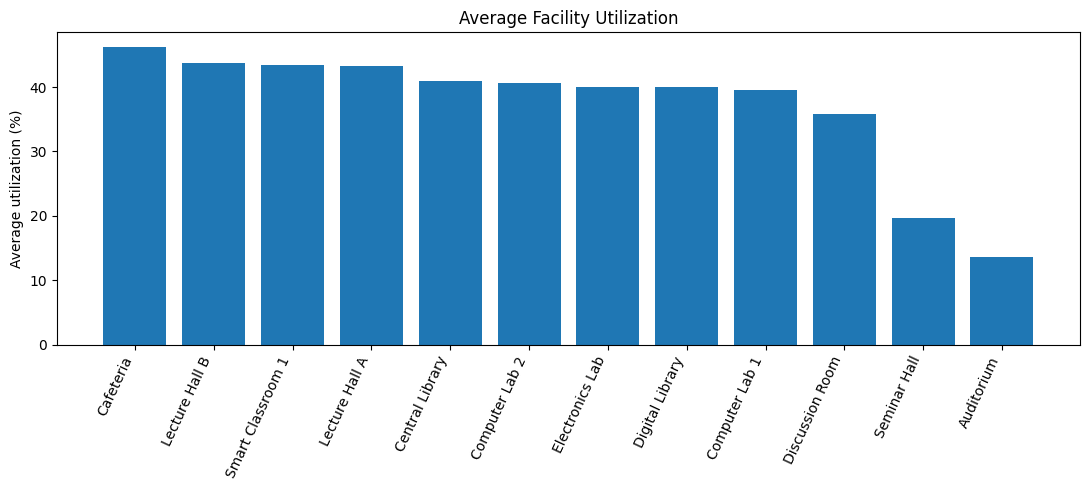

In [ ]:
# 4. Exploratory Data Analysis (EDA)
# Facility utilization
facility_util = (occupancy.groupby(['facility','type','capacity'], as_index=False)
                 .agg(avg_occupancy=('count_for_utilization','mean'),
                      peak_occupancy=('count_for_utilization','max'),
                      avg_utilization_pct=('utilization_pct','mean'),
                      readings=('count','size')))
facility_util = facility_util.sort_values('avg_utilization_pct', ascending=False)
display(facility_util.round(2))

plt.figure(figsize=(11,5))
plt.bar(facility_util['facility'], facility_util['avg_utilization_pct'])
plt.xticks(rotation=65, ha='right')
plt.ylabel('Average utilization (%)')
plt.title('Average Facility Utilization')
plt.tight_layout()
plt.show()


,hour,avg_occupancy,avg_utilization_pct
0,8,29.13,31.23
1,10,44.87,45.84
2,12,25.00,25.89
3,14,43.14,44.80
4,16,43.74,44.51
5,18,29.14,31.27


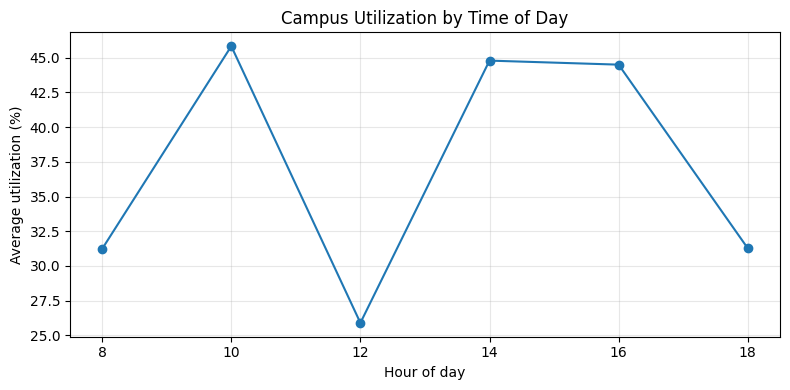

In [ ]:
# Peak-time analysis
peak_time = occupancy.groupby('hour', as_index=False).agg(
    avg_occupancy=('count_for_utilization','mean'),
    avg_utilization_pct=('utilization_pct','mean'))
display(peak_time.round(2))
plt.figure(figsize=(8,4))
plt.plot(peak_time['hour'], peak_time['avg_utilization_pct'], marker='o')
plt.xlabel('Hour of day')
plt.ylabel('Average utilization (%)')
plt.title('Campus Utilization by Time of Day')
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()


,exam_period,avg_occupancy,avg_utilization_pct,readings
0,False,34.49,35.89,5616
1,True,44.57,46.13,864


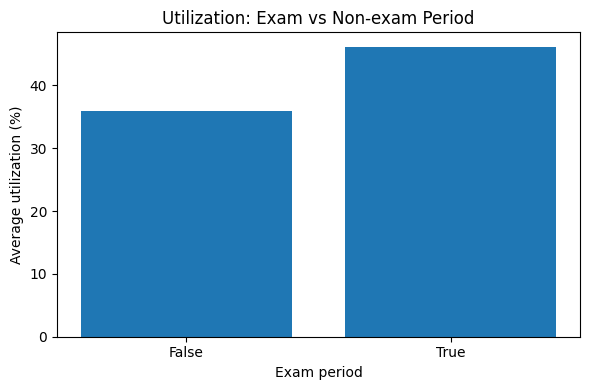

In [ ]:
# Exam-period comparison
# Build a clean date-level join using date strings.
occ_date = occupancy.copy()
occ_date['date_key'] = occ_date['timestamp'].dt.strftime('%Y-%m-%d')
calendar2 = calendar.copy()
calendar2['date_key'] = pd.to_datetime(calendar2['date']).dt.strftime('%Y-%m-%d')
occ_date = occ_date.merge(calendar2[['date_key','exam_period','event','working_day']], on='date_key', how='left')
exam_comparison = occ_date.groupby('exam_period', as_index=False).agg(
    avg_occupancy=('count_for_utilization','mean'),
    avg_utilization_pct=('utilization_pct','mean'),
    readings=('count','size'))
display(exam_comparison.round(2))
plt.figure(figsize=(6,4))
plt.bar(exam_comparison['exam_period'].astype(str), exam_comparison['avg_utilization_pct'])
plt.xlabel('Exam period')
plt.ylabel('Average utilization (%)')
plt.title('Utilization: Exam vs Non-exam Period')
plt.tight_layout()
plt.show()


,facility,total_downtime_hours,maintenance_records
4,Computer Lab 2,90.0,6
11,Smart Classroom 1,74.0,6
10,Seminar Hall,58.0,6
8,Lecture Hall A,52.0,7
2,Central Library,40.0,5
1,Cafeteria,28.0,6
3,Computer Lab 1,24.0,6
0,Auditorium,22.0,5
7,Electronics Lab,22.0,4
5,Digital Library,16.0,6


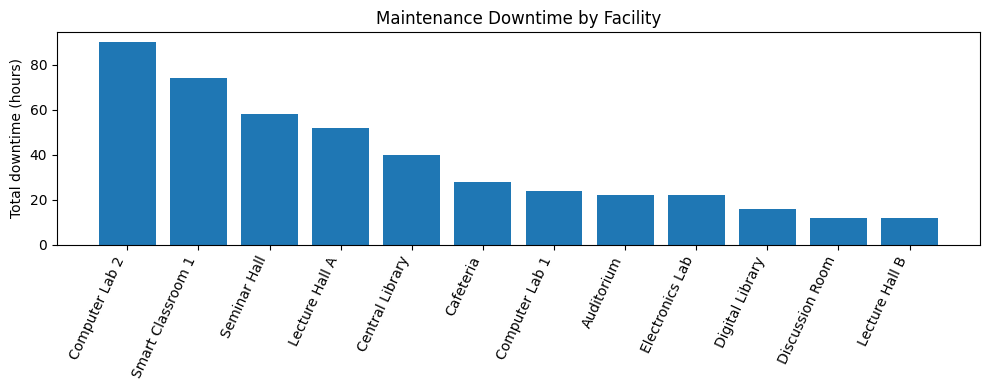

In [ ]:
# Maintenance downtime analysis
maintenance_clean = maintenance.merge(facilities[['facility','type','capacity','block']], on='facility', how='left')
maintenance_clean['downtime_hours'] = maintenance_clean['downtime_hours'].fillna(
    maintenance_clean.groupby('facility')['downtime_hours'].transform('median'))
maintenance_clean['downtime_hours'] = maintenance_clean['downtime_hours'].fillna(0)
downtime_summary = maintenance_clean.groupby('facility', as_index=False).agg(
    total_downtime_hours=('downtime_hours','sum'),
    maintenance_records=('maintenance_id','count'))
downtime_summary = downtime_summary.sort_values('total_downtime_hours', ascending=False)
display(downtime_summary)
plt.figure(figsize=(10,4))
plt.bar(downtime_summary['facility'], downtime_summary['total_downtime_hours'])
plt.xticks(rotation=65, ha='right')
plt.ylabel('Total downtime (hours)')
plt.title('Maintenance Downtime by Facility')
plt.tight_layout()
plt.show()


,facility,capacity,avg_utilization_pct,underused_flag
1,Cafeteria,150,46.20,False
9,Lecture Hall B,90,43.71,False
11,Smart Classroom 1,60,43.46,False
8,Lecture Hall A,120,43.34,False
2,Central Library,180,41.01,False
4,Computer Lab 2,45,40.59,False
7,Electronics Lab,40,40.06,False
5,Digital Library,70,40.05,False
3,Computer Lab 1,50,39.56,False
6,Discussion Room,20,35.77,False


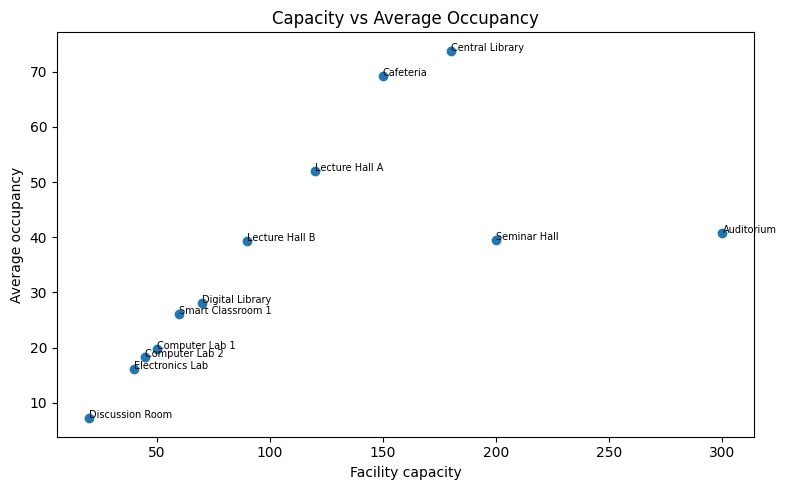

In [ ]:
# Capacity comparison and underused rooms
facility_util['underused_flag'] = facility_util['avg_utilization_pct'] < 25
display(facility_util[['facility','capacity','avg_utilization_pct','underused_flag']].round(2))
plt.figure(figsize=(8,5))
plt.scatter(facility_util['capacity'], facility_util['avg_occupancy'])
for _, row in facility_util.iterrows():
    plt.annotate(row['facility'], (row['capacity'], row['avg_occupancy']), fontsize=7)
plt.xlabel('Facility capacity')
plt.ylabel('Average occupancy')
plt.title('Capacity vs Average Occupancy')
plt.tight_layout()
plt.show()


In [ ]:
# 5. Feature engineering and feature selection
# Create a modeling table: predict occupancy count from time, facility characteristics, and calendar status.
model_df = occ_date.copy()
model_df['hour'] = model_df['timestamp'].dt.hour
model_df['day_of_week'] = model_df['timestamp'].dt.dayofweek
model_df['month'] = model_df['timestamp'].dt.month
model_df['is_weekend'] = (model_df['day_of_week'] >= 5).astype(int)
model_df['exam_period'] = model_df['exam_period'].fillna(False).astype(int)
model_df['working_day'] = model_df['working_day'].fillna(False).astype(int)
model_df['event'] = model_df['event'].fillna('Unknown')
model_df['count_target'] = model_df['count_for_utilization']

feature_cols = ['hour','day_of_week','month','is_weekend','exam_period','working_day','capacity','type','block','facility']
target_col = 'count_target'
model_df = model_df.dropna(subset=[target_col])
display(model_df[feature_cols + [target_col]].head())
print("Target:", target_col)
print("Input features:", feature_cols)


,hour,day_of_week,month,is_weekend,exam_period,working_day,capacity,type,block,facility,count_target
0,8,0,1,0,0,1,120,Classroom,Block A,Lecture Hall A,57.0
1,10,0,1,0,0,1,120,Classroom,Block A,Lecture Hall A,68.0
2,12,0,1,0,0,1,120,Classroom,Block A,Lecture Hall A,49.0
3,14,0,1,0,0,1,120,Classroom,Block A,Lecture Hall A,67.0
4,16,0,1,0,0,1,120,Classroom,Block A,Lecture Hall A,68.0


Target: count_target
Input features: ['hour', 'day_of_week', 'month', 'is_weekend', 'exam_period', 'working_day', 'capacity', 'type', 'block', 'facility']


In [ ]:
# 6. Machine learning — Random Forest Regression
# A time-ordered split is used so later dates are held out for evaluation.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_df = model_df.sort_values('timestamp')
split_idx = int(len(model_df) * 0.8)
train_df = model_df.iloc[:split_idx]
test_df = model_df.iloc[split_idx:]
X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

categorical_features = ['type','block','facility']
numeric_features = [c for c in feature_cols if c not in categorical_features]
preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('numeric', 'passthrough', numeric_features)
])
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=120, max_depth=14, min_samples_leaf=2, random_state=42, n_jobs=-1))
])
model.fit(X_train, y_train)
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.3f}")


MAE: 10.85
RMSE: 20.59
R² Score: 0.700


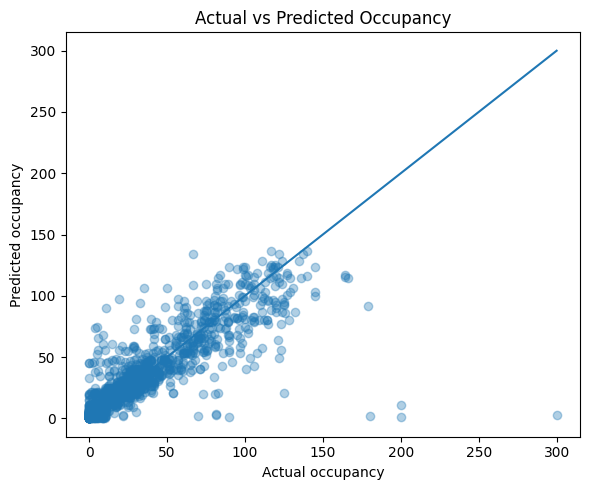

In [ ]:
# Actual vs predicted visualization
plt.figure(figsize=(6,5))
plt.scatter(y_test, pred, alpha=.35)
low = min(float(y_test.min()), float(np.min(pred)))
high = max(float(y_test.max()), float(np.max(pred)))
plt.plot([low, high], [low, high])
plt.xlabel('Actual occupancy')
plt.ylabel('Predicted occupancy')
plt.title('Actual vs Predicted Occupancy')
plt.tight_layout()
plt.show()


In [ ]:
# 7. Generate practical findings from this synthetic dataset
most_used = facility_util.iloc[0]
least_used = facility_util.iloc[-1]
peak_row = peak_time.loc[peak_time['avg_utilization_pct'].idxmax()]
exam_rows = exam_comparison.set_index('exam_period')
top_downtime = downtime_summary.iloc[0]
print(f"Highest average utilization: {most_used['facility']} ({most_used['avg_utilization_pct']:.1f}%).")
print(f"Lowest average utilization: {least_used['facility']} ({least_used['avg_utilization_pct']:.1f}%).")
print(f"Peak recorded time slot: {int(peak_row['hour']):02d}:00 ({peak_row['avg_utilization_pct']:.1f}% average utilization).")
print(f"Facility with highest recorded downtime: {top_downtime['facility']} ({top_downtime['total_downtime_hours']:.0f} hours).")
if False in exam_rows.index and True in exam_rows.index:
    change = exam_rows.loc[True, 'avg_utilization_pct'] - exam_rows.loc[False, 'avg_utilization_pct']
    print(f"Exam-period utilization difference: {change:+.1f} percentage points.")
print("Reminder: these findings describe synthetic demo data, not a real campus.")


Highest average utilization: Cafeteria (46.2%).
Lowest average utilization: Auditorium (13.6%).
Peak recorded time slot: 10:00 (45.8% average utilization).
Facility with highest recorded downtime: Computer Lab 2 (90 hours).
Exam-period utilization difference: +10.2 percentage points.
Reminder: these findings describe synthetic demo data, not a real campus.


In [ ]:
# 8. Export cleaned data and summaries for Excel
# Export occupancy rows with core columns and analysis summaries.
occupancy_export = occ_date.copy()
occupancy_export.to_csv('/content/cleaned_occupancy.csv', index=False)
bookings.to_csv('/content/cleaned_bookings.csv', index=False)
maintenance_clean.to_csv('/content/cleaned_maintenance.csv', index=False)
with pd.ExcelWriter('/content/campus_facility_analysis.xlsx', engine='openpyxl') as writer:
    quality_df.to_excel(writer, sheet_name='Data_Quality', index=False)
    facility_util.to_excel(writer, sheet_name='Facility_Utilization', index=False)
    peak_time.to_excel(writer, sheet_name='Peak_Time', index=False)
    exam_comparison.to_excel(writer, sheet_name='Exam_Comparison', index=False)
    downtime_summary.to_excel(writer, sheet_name='Downtime', index=False)
    occupancy_export.to_excel(writer, sheet_name='Cleaned_Occupancy', index=False)
print("Excel workbook and cleaned CSVs created.")


Excel workbook and cleaned CSVs created.


In [ ]:
# 9. Download outputs
from google.colab import files
files.download('/content/campus_facility_analysis.xlsx')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>